## Respiratory Data
This notebook will exist to turn respiratory data into a single, usable dataframe that will flag a given timestamp into one of three different categories of quality-control:
- Acceptable -> We are enough within the breathing range to be confident about data quality at this timestamp
- Shaky -> We are approaching the edges of the acceptable breathing-rate range. We should look at this more closely.
- Unacceptable -> The respiratory rate falls outside of the acceptable range.

### Files Used
- `unofficial-data-files\2.1_respiratory_data_0.csv` -> respiration belt force (N) and respiratory rate (RR, breaths per minute)
- `data-files\2.1_G1_biometrics.csv` -> Contains phase markers

### Respiration Belt Specifications
| Spec | Value |
|---|---|
| Force range | 0–50 N |
| Force resolution | 0.01 N |
| Force response time | 50 ms |
| RR sample window | 30 s |
| RR advance interval | 10 s |

What this tells us about the file. These points come from the device, so they are taken as given and not re-derived from the data:
- `force` is measured continuously. It is the belt's raw stretch signal.
- `RR` is calculated from `force` over a 30 s window, and a new calculation is made every 10 s. **A row with an `RR` value is a row where the device made a calculation. An empty `RR` means no calculation was made at that row, not that a value is missing.**
- Consecutive RR windows overlap by 20 s, so each moment of the recording is covered by up to 3 readings.

### Sources I'm Using To Determine Respiratory Thresholds
- https://doi.org/10.3389/fpsyg.2017.00213 -> Original HRV Reading Assignment
    - 9-24 Breaths Per Minute is the acceptable breathing range

### Assumptions
1. **Each RR reading describes the 30 s *before* it.** The specs give the window length but not where it sits relative to the reading. The device calculates RR live as the recording runs, so it can only use `force` samples it has already received. The window therefore ends at the reading.
2. **RR = 0 is a real measurement, not a missing value.** Every `RR` value is a calculation the device made, so 0 means it counted no breaths in its 30 s window. That is below 9 breaths/min, so it is classified Unacceptable like any other low reading. *(The "Belt Disturbances" section looks at what the belt signal is doing during these readings.)*
3. **The respiratory file's `timestamp_unix` uses the same clock as the biometrics file.** This is supported by the marker agreement check in "Attaching Experiment Phases".

### Important Data Processing Steps To Note
**1. Columns kept and dropped.** *(Code: "Loading & Dropping Columns" section.)*
- Kept: `timestamp_unix`, `force` and `RR`.
- Dropped: `timestamp` (a text copy of `timestamp_unix`), and the file's own `event_marker` and `condition` (replaced by the biometrics phase markers, step 2).
- No rows are removed.

**2. Phases are attached from the biometrics file, not taken from the respiratory file.** *(Code: "Attaching Experiment Phases" section.)*
- Same method as `001_movement-artifacts.ipynb`: each sample takes the most recent biometrics `event_marker` at or before its timestamp, and sub-phases are kept. This way every notebook uses one source for phases.

**3. RR readings are classified into the three categories.** *(Code: "Classifying RR Readings" section.)*
- Acceptable: 12–21 breaths/min. Shaky: 9–12 or 21–24. Unacceptable: below 9 or above 24. These follow the 9–24 range from the source above, with `ACCEPTABLE_RANGE_DANGER_ZONE` = 3.
- RR = 0 readings are Unacceptable (Assumption 2).

**4. The belt signal is checked against the force specs.** *(Code: "Checking Force Against The Specs" and "Belt Disturbances" sections.)*
- Checks for readings that hit the 50 N ceiling (where the signal would be cut off), and for large belt disturbances inside each RR window.
- These checks describe the readings. They do not change the categories.

**5. Mask: each moment takes the quality of the first RR reading at or after it.** *(Code: "Respiratory Mask For HRV Cleaning" section.)*
- By Assumption 1, that reading's 30 s window always covers the moment, and every moment gets exactly one reading.
- `keep` is True for Acceptable and Shaky, False for Unacceptable. Samples after the last RR reading are not covered by any window and are labelled `No reading` (`keep` = False).
- Saved to `processed-data/2.1_G1_respiratory_mask.csv` (`timestamp_unix`, `RR`, `resp_quality`, `keep`) for use in `999_hrv-cleaning.ipynb`.

### Global Variables & Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESP_FILE = Path("../unofficial-data-files/2.1_respiratory_data_0.csv")
BIOMETRICS_FILE = Path("../data-files/2.1_G1_biometrics.csv")
MASK_OUTPUT_FILE = Path("../processed-data/2.1_G1_respiratory_mask.csv")

ACCEPTABLE_RANGE_LOW = 9
ACCEPTABLE_RANGE_HIGH = 24
ACCEPTABLE_RANGE_DANGER_ZONE = 3 # So fully acceptable range becomes 12-21

# Respiration belt specs
FORCE_RANGE_MAX_N = 50 # Measurement range is 0-50 N
FORCE_RESOLUTION_N = 0.01
FORCE_RESPONSE_TIME_S = 0.05
RR_WINDOW_S = 30 # Each RR reading is calculated over the 30 s before it (Assumption 1)
RR_ADVANCE_S = 10 # A new RR reading every 10 s

LARGE_EXCURSION_N = 10 # Marks a belt disturbance; ~1.5x the median excursion during Acceptable readings (see "Belt Disturbances")

QUALITY_ORDER = ["Acceptable", "Shaky", "Unacceptable"]
QUALITY_COLORS = {"Acceptable": "#0ca30c", "Shaky": "#fab219", "Unacceptable": "#d03b3b", "No reading": "#8a8984"}

### Loading & Dropping Columns
Columns dropped:
- `timestamp`: a text copy of `timestamp_unix`.
- `event_marker` and `condition`: phase markers are taken from the biometrics file instead, so every notebook uses the same source. They are kept in `raw` only long enough for the agreement check below.

`force` is continuous and `RR` is calculated every 10 s, so the only check here is that the number of RR readings matches what a 10 s advance gives over the recording's length (i.e. the file is complete).

In [2]:
raw = pd.read_csv(RESP_FILE)
resp_df = raw[["timestamp_unix", "force", "RR"]].copy()
resp_df["minutes"] = (resp_df["timestamp_unix"] - resp_df["timestamp_unix"].iloc[0]) / 60

duration_s = resp_df["timestamp_unix"].iloc[-1] - resp_df["timestamp_unix"].iloc[0]
print(f"Rows: {len(resp_df)}, duration {duration_s / 60:.2f} min")
print(f"RR readings: {resp_df['RR'].notna().sum()} (a {RR_ADVANCE_S} s advance over this duration gives {duration_s / RR_ADVANCE_S:.0f})")
resp_df.head()

Rows: 50799, duration 84.65 min
RR readings: 508 (a 10 s advance over this duration gives 508)


,timestamp_unix,force,RR,minutes
0,1.757035e+09,9.108154,8.804109,0.000000
1,1.757035e+09,9.189911,NaN,0.000018
2,1.757035e+09,9.233345,NaN,0.000027
3,1.757035e+09,9.246124,NaN,0.000037
4,1.757035e+09,9.271667,NaN,0.000045


### Attaching Experiment Phases
Same method as `001_movement-artifacts.ipynb`: each sample gets the most recent biometrics `event_marker` at or before its timestamp, and sub-phases are kept as their own phases. The check below compares this with the respiratory file's own `event_marker` column (which spells the first phase `start_up` rather than `startup`). Close agreement supports Assumption 3 (the two files share a clock).

In [3]:
phases = (
    pd.read_csv(BIOMETRICS_FILE, usecols=["timestamp_unix", "event_marker"])
    .dropna()
    .sort_values("timestamp_unix")
    .rename(columns={"event_marker": "phase", "timestamp_unix": "phase_start"})
)
resp_df = pd.merge_asof(resp_df, phases, left_on="timestamp_unix", right_on="phase_start", direction="backward").drop(columns="phase_start")
resp_df["phase"] = resp_df["phase"].fillna("unlabeled")

own_marker = raw["event_marker"].replace("start_up", "startup")
agree = own_marker == resp_df["phase"]
print(f"Respiratory recording starts {resp_df['timestamp_unix'].iloc[0] - phases['phase_start'].iloc[0]:.1f}s after the first biometrics marker")
print(f"Samples where the file's own marker matches the biometrics marker: {agree.sum()} of {len(agree)} ({100 * agree.mean():.2f}%)")
boundary_times = resp_df.loc[resp_df["phase"] != resp_df["phase"].shift(), "timestamp_unix"].to_numpy()
gap_to_boundary = np.abs(resp_df.loc[~agree, "timestamp_unix"].to_numpy()[:, None] - boundary_times[None, :]).min(axis=1)
print(f"Disagreeing samples: {len(agree) - agree.sum()}, all within {gap_to_boundary.max():.2f}s of a phase boundary")

run_id = (resp_df["phase"] != resp_df["phase"].shift()).cumsum()
phase_segments = resp_df.groupby(run_id).agg(
    phase=("phase", "first"), start=("minutes", "first"), end=("minutes", "last")
).reset_index(drop=True)
phase_segments.head()

Respiratory recording starts 12.2s after the first biometrics marker
Samples where the file's own marker matches the biometrics marker: 50772 of 50799 (99.95%)
Disagreeing samples: 27, all within 0.21s of a phase boundary


,phase,start,end
0,startup,0.000000,0.116544
1,biometric_baseline,0.118206,2.116576
2,subject_idle,2.118097,5.113077
3,ser_baseline,5.114547,7.879551
4,subject_idle,7.881056,8.046581


### Classifying RR Readings
Each RR reading is classified with the thresholds above:
- **Acceptable**: 12–21 breaths/min
- **Shaky**: 9–12 or 21–24 breaths/min (inside the 9–24 range, within `ACCEPTABLE_RANGE_DANGER_ZONE` of an edge)
- **Unacceptable**: below 9 or above 24 breaths/min, including RR = 0 (Assumption 2)

In [4]:
def classify_rr(rr):
    if rr < ACCEPTABLE_RANGE_LOW or rr > ACCEPTABLE_RANGE_HIGH:
        return "Unacceptable"
    if rr < ACCEPTABLE_RANGE_LOW + ACCEPTABLE_RANGE_DANGER_ZONE or rr > ACCEPTABLE_RANGE_HIGH - ACCEPTABLE_RANGE_DANGER_ZONE:
        return "Shaky"
    return "Acceptable"

rr_df = resp_df.dropna(subset=["RR"])[["timestamp_unix", "minutes", "phase", "RR"]].reset_index(drop=True)
rr_df["quality"] = pd.Categorical(rr_df["RR"].map(classify_rr), categories=QUALITY_ORDER)

unacceptable = rr_df[rr_df["quality"] == "Unacceptable"]
print(f"Unacceptable readings: {(unacceptable['RR'] == 0).sum()} at RR = 0, "
      f"{((unacceptable['RR'] > 0) & (unacceptable['RR'] < ACCEPTABLE_RANGE_LOW)).sum()} between 0 and {ACCEPTABLE_RANGE_LOW}, "
      f"{(unacceptable['RR'] > ACCEPTABLE_RANGE_HIGH).sum()} above {ACCEPTABLE_RANGE_HIGH}")
print(f"Readings above {ACCEPTABLE_RANGE_HIGH}, at minute:", rr_df.loc[rr_df["RR"] > ACCEPTABLE_RANGE_HIGH, "minutes"].round(1).tolist())
print(rr_df["RR"].describe(percentiles=[.05, .25, .5, .75, .95]).round(2).to_string())
rr_df["quality"].value_counts().reindex(QUALITY_ORDER).to_frame("readings").assign(pct=lambda d: (100 * d["readings"] / d["readings"].sum()).round(1))

Unacceptable readings: 53 at RR = 0, 69 between 0 and 9, 13 above 24
Readings above 24, at minute: [5.3, 10.3, 10.6, 20.0, 20.1, 23.3, 81.3, 81.5, 83.3, 83.5, 83.7, 83.8, 84.0]
count    508.00
mean      12.87
std        6.44
min        0.00
5%         0.00
25%        9.22
50%       13.84
75%       17.48
95%       21.90
max       26.79


,readings,pct
quality,,
Acceptable,281,55.3
Shaky,92,18.1
Unacceptable,135,26.6


### Checking Force Against The Specs
Three checks of the `force` signal against the belt specs:
- **Response time**: if samples arrive more slowly than the 50 ms response time, each sample is a settled reading and is not blurred by sensor lag.
- **Resolution**: if the belt typically moves by far more than 0.01 N within an RR window, resolution is not a limit on counting breaths. This is measured as the median max-minus-min of `force` over a 30 s window.
- **Range**: samples near the 50 N ceiling may be cut off. The RR readings whose 30 s window contains such a sample are listed.

In [5]:
t = resp_df["timestamp_unix"].to_numpy()
force_by_time = resp_df.set_index(pd.to_datetime(resp_df["timestamp_unix"], unit="s"))["force"]
window_range = force_by_time.rolling(f"{RR_WINDOW_S}s").max() - force_by_time.rolling(f"{RR_WINDOW_S}s").min()

print(f"Median sample interval: {np.median(np.diff(t)) * 1000:.0f} ms (response time {FORCE_RESPONSE_TIME_S * 1000:.0f} ms)")
print(f"Median force range over a {RR_WINDOW_S} s window: {window_range.median():.2f} N (resolution {FORCE_RESOLUTION_N} N)")
print(f"Force range: {resp_df['force'].min():.2f}-{resp_df['force'].max():.2f} N (sensor range 0-{FORCE_RANGE_MAX_N} N)")

near_max = resp_df[resp_df["force"] >= FORCE_RANGE_MAX_N - 1]
print(f"Samples within 1 N of the ceiling: {len(near_max)}, at {near_max['minutes'].round(2).unique().tolist()} min ({near_max['phase'].unique().tolist()})")
covers_near_max = [((r - RR_WINDOW_S <= near_max["timestamp_unix"]) & (near_max["timestamp_unix"] <= r)).any() for r in rr_df["timestamp_unix"]]
rr_df.loc[covers_near_max, ["minutes", "phase", "RR", "quality"]]

Median sample interval: 90 ms (response time 50 ms)
Median force range over a 30 s window: 11.77 N (resolution 0.01 N)
Force range: 2.82-49.98 N (sensor range 0-50 N)
Samples within 1 N of the ceiling: 4, at [45.35, 45.36] min (['break_1'])


,minutes,phase,RR,quality
273,45.483237,break_1,0.0,Unacceptable
274,45.649695,break_1,0.0,Unacceptable
275,45.816748,break_1,0.0,Unacceptable


### Belt Disturbances
Checks whether Unacceptable readings, and RR = 0 in particular, line up with large disturbances in the belt signal, such as a pull on the belt from moving or changing posture. For each RR reading, the **largest excursion** is the biggest distance between `force` and its 30 s rolling median within that reading's 30 s window. `LARGE_EXCURSION_N` (10 N) is used as a marker for a disturbance. It sits at ~1.5× the median excursion of Acceptable readings, so ordinary breathing rarely reaches it. It is only used to describe readings here, not to classify them.

Unacceptable readings are split into RR = 0 and RR > 0 here so the two can be compared. The first reading is at the recording's first sample, so its window has no `force` data and it has no excursion value.

In [6]:
excursion = (force_by_time - force_by_time.rolling(f"{RR_WINDOW_S}s", center=True).median()).abs().to_numpy()
window_start = np.searchsorted(t, rr_df["timestamp_unix"] - RR_WINDOW_S)
window_end = np.searchsorted(t, rr_df["timestamp_unix"])
rr_df["max_excursion_n"] = [excursion[a:b].max() if b > a else np.nan for a, b in zip(window_start, window_end)]

reading_group = np.where(rr_df["RR"] == 0, "Unacceptable (RR = 0)",
                         np.where(rr_df["quality"] == "Unacceptable", "Unacceptable (RR > 0)", rr_df["quality"].astype(str)))
rr_df.groupby(reading_group)["max_excursion_n"].agg(
    readings="count", median="median", minimum="min",
    over_large=lambda s: (s > LARGE_EXCURSION_N).mean(),
).reindex(["Acceptable", "Shaky", "Unacceptable (RR > 0)", "Unacceptable (RR = 0)"]).round(2)

,readings,median,minimum,over_large
Acceptable,281,6.73,3.12,0.17
Shaky,92,8.23,3.33,0.38
Unacceptable (RR > 0),81,12.91,2.23,0.71
Unacceptable (RR = 0),53,21.73,11.27,1.00


The same comparison for the two task/PRS blocks, since the phase breakdown below shows the second block has the worst respiratory quality.

In [7]:
block = np.select(
    [rr_df["phase"].str.match(r"^(task|prs)_1"), rr_df["phase"].str.match(r"^(task|prs)_2")],
    ["task_1 / prs_1", "task_2 / prs_2"], "everything else",
)
rr_df.groupby(block).agg(
    readings=("RR", "size"),
    median_excursion_n=("max_excursion_n", "median"),
    acceptable=("quality", lambda q: (q == "Acceptable").mean()),
    unacceptable=("quality", lambda q: (q == "Unacceptable").mean()),
    rr_zero=("RR", lambda s: (s == 0).mean()),
).round(2)

,readings,median_excursion_n,acceptable,unacceptable,rr_zero
everything else,376,7.02,0.61,0.22,0.09
task_1 / prs_1,67,10.14,0.58,0.19,0.03
task_2 / prs_2,65,15.05,0.17,0.62,0.28


### Respiratory Rate Over Time
Dots are RR readings, coloured by quality. Horizontal bands mark the 9–24 range (light) and the 12–21 fully acceptable range (darker). Vertical bands mark phases, and phases longer than 2 minutes are labeled.

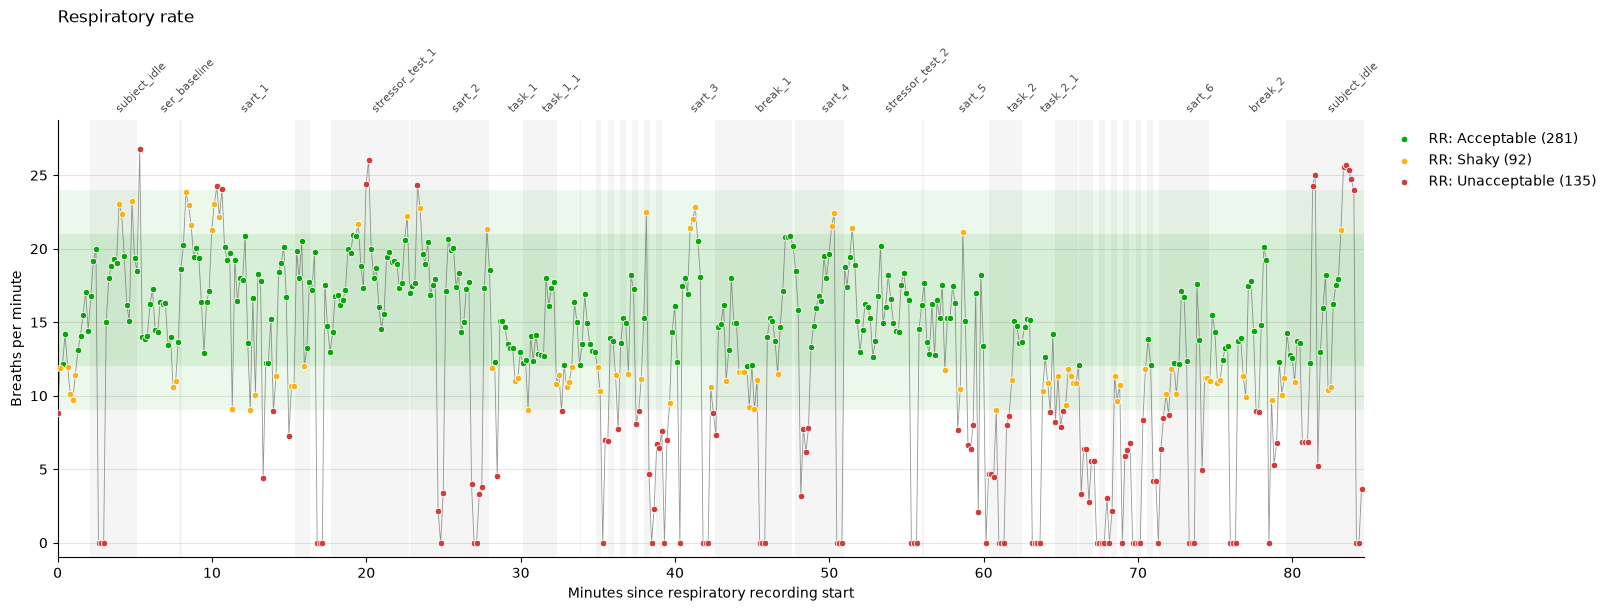

In [8]:
fig, ax = plt.subplots(figsize=(16, 6), constrained_layout=True)

for i, seg in phase_segments.iterrows():
    if i % 2 == 0:
        ax.axvspan(seg["start"], seg["end"], color="#000000", alpha=0.04, lw=0)
ax.axhspan(ACCEPTABLE_RANGE_LOW, ACCEPTABLE_RANGE_HIGH, color=QUALITY_COLORS["Acceptable"], alpha=0.07, lw=0)
ax.axhspan(ACCEPTABLE_RANGE_LOW + ACCEPTABLE_RANGE_DANGER_ZONE, ACCEPTABLE_RANGE_HIGH - ACCEPTABLE_RANGE_DANGER_ZONE,
           color=QUALITY_COLORS["Acceptable"], alpha=0.10, lw=0)

ax.plot(rr_df["minutes"], rr_df["RR"], color="#52514e", lw=0.6, alpha=0.6)
for q in QUALITY_ORDER:
    pts = rr_df[rr_df["quality"] == q]
    ax.scatter(pts["minutes"], pts["RR"], s=22, color=QUALITY_COLORS[q], edgecolor="white", linewidth=0.6, zorder=3,
               label=f"RR: {q} ({len(pts)})")

for _, seg in phase_segments.iterrows():
    if seg["end"] - seg["start"] >= 2:
        ax.text((seg["start"] + seg["end"]) / 2, 1.01, seg["phase"], transform=ax.get_xaxis_transform(),
                rotation=45, ha="left", va="bottom", fontsize=8, color="#52514e")

ax.set_xlim(0, resp_df["minutes"].iloc[-1])
ax.set_ylim(-1, rr_df["RR"].max() + 2)
ax.set_xlabel("Minutes since respiratory recording start")
ax.set_ylabel("Breaths per minute")
ax.set_title("Respiratory rate", loc="left", pad=70)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

### Distribution Of Respiratory Rate
Histogram of all RR readings, with bars coloured by quality category. RR = 0 readings make up the bar at 0.

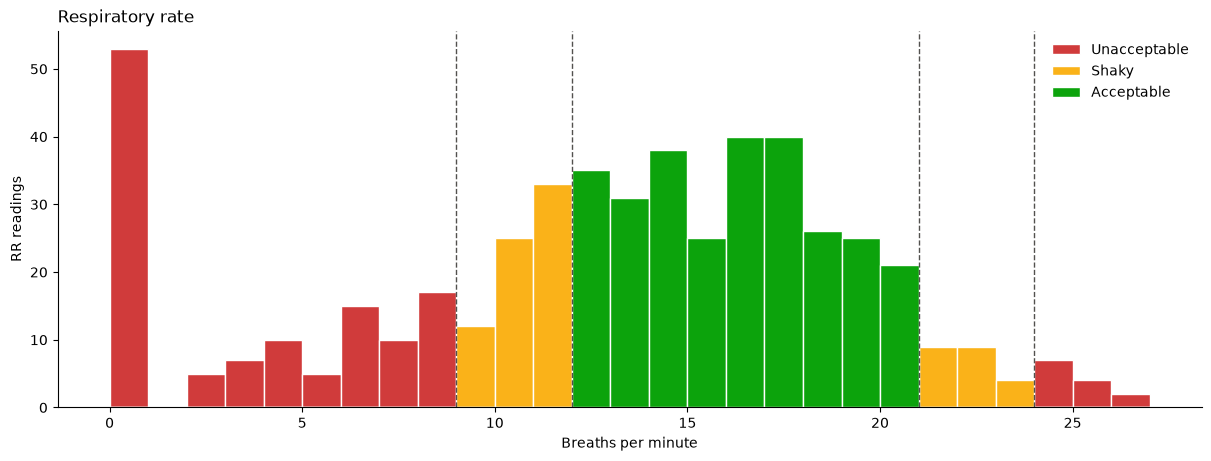

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
bins = np.arange(0, np.ceil(rr_df["RR"].max()) + 1, 1)
for q in ["Unacceptable", "Shaky", "Acceptable"]:
    ax.hist(rr_df.loc[rr_df["quality"] == q, "RR"], bins=bins, color=QUALITY_COLORS[q], label=q,
            edgecolor="white", linewidth=1)
for x in [ACCEPTABLE_RANGE_LOW, ACCEPTABLE_RANGE_LOW + ACCEPTABLE_RANGE_DANGER_ZONE,
          ACCEPTABLE_RANGE_HIGH - ACCEPTABLE_RANGE_DANGER_ZONE, ACCEPTABLE_RANGE_HIGH]:
    ax.axvline(x, color="#52514e", lw=1, ls="--")
ax.set_xlabel("Breaths per minute")
ax.set_ylabel("RR readings")
ax.set_title("Respiratory rate", loc="left")
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

### Quality By Phase
Share of each phase's RR readings in each quality category. Phases are listed in the order they first occur, with the number of readings in brackets. PRS questionnaire items last only ~22 seconds (2–3 readings each), so their shares are rough.

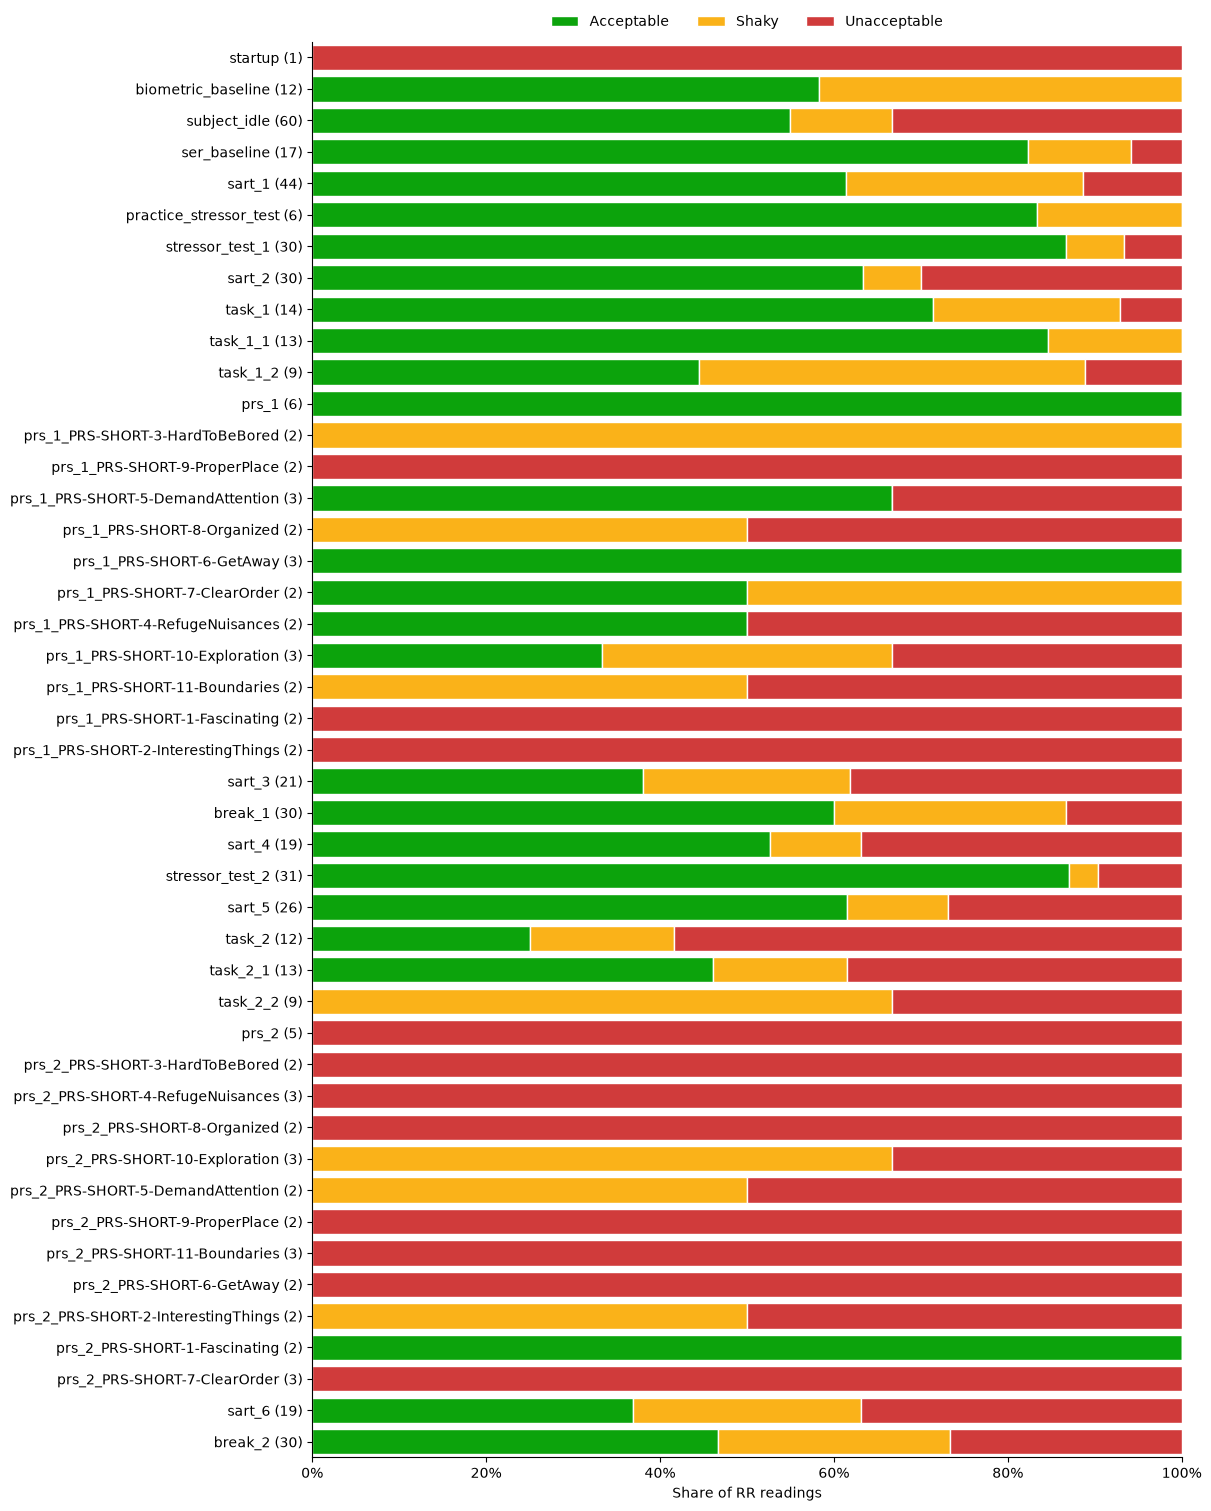

In [10]:
phase_order = list(dict.fromkeys(rr_df["phase"]))
quality_by_phase = pd.crosstab(rr_df["phase"], rr_df["quality"]).reindex(index=phase_order, columns=QUALITY_ORDER, fill_value=0)
shares = quality_by_phase.div(quality_by_phase.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 0.3 * len(phase_order) + 1.5), constrained_layout=True)
left = np.zeros(len(shares))
for q in QUALITY_ORDER:
    ax.barh(range(len(shares)), shares[q], left=left, color=QUALITY_COLORS[q], label=q, edgecolor="white", linewidth=1, height=0.8)
    left += shares[q].to_numpy()
ax.set_yticks(range(len(shares)), [f"{p} ({n})" for p, n in zip(shares.index, quality_by_phase.sum(axis=1))])
ax.set_ylim(len(shares) - 0.5, -0.5)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Share of RR readings")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [11]:
quality_by_phase.assign(
    readings=quality_by_phase.sum(axis=1),
    rr_zero=rr_df.groupby("phase")["RR"].apply(lambda s: (s == 0).sum()),
    RR_median=rr_df.groupby("phase")["RR"].median().round(2),
)

quality,Acceptable,Shaky,Unacceptable,readings,rr_zero,RR_median
phase,,,,,,
startup,0,0,1,1,0,8.80
biometric_baseline,7,5,0,12,0,12.62
subject_idle,33,7,20,60,8,16.19
ser_baseline,14,2,1,17,0,14.31
sart_1,27,12,5,44,0,17.91
practice_stressor_test,5,1,0,6,0,17.89
stressor_test_1,26,2,2,30,0,18.91
sart_2,19,2,9,30,3,17.44
task_1,10,3,1,14,0,13.10


### Observations
Each observation names the section whose output supports it.
- **The file is complete and lines up with the biometrics file** *(Loading & Dropping Columns, Attaching Experiment Phases)*: there are 508 RR readings, which matches the 508 a 10 s advance gives over the 84.65 min recording. The file's own phase markers agree with the biometrics markers on 99.95% of samples, and the 27 that differ are all within 0.21 s of a phase boundary. The recording starts 12.2 s after the first biometrics marker.
- **The belt's specs are not a limit on this data** *(Checking Force Against The Specs)*: samples arrive every ~90 ms, slower than the 50 ms response time, so each sample is a settled reading. Within a typical 30 s window the belt moves ~11.8 N, over 1000× the 0.01 N resolution.
- **The 50 N ceiling is reached once** *(Checking Force Against The Specs)*: force ranges 2.82–49.98 N. Only 4 samples come within 1 N of the ceiling, all at ~45.35 min in `break_1`. The 3 RR readings whose windows contain them are all RR = 0, so any clipping only affects readings that are already Unacceptable.
- **73% of RR readings are usable** *(Classifying RR Readings)*: 55.3% Acceptable, 18.1% Shaky and 26.6% Unacceptable. Of the 135 Unacceptable readings, 53 are RR = 0, 69 are between 0 and 9, and 13 are above 24. Unacceptable readings are mostly too slow.
- **Zero and slow readings happen when the belt is disturbed** *(Belt Disturbances)*: every RR = 0 reading has an excursion above 10 N in its window (minimum 11.27 N, median 21.73 N), and so do 71% of the other Unacceptable readings (median 12.91 N). For Acceptable readings it is 17% (median 6.73 N). Large disturbances still occur during some Acceptable readings, so a disturbance alone doesn't make a reading Unacceptable.
- **Breathing slows over the session** *(Respiratory Rate Over Time, Quality By Phase)*: phase medians are ~18–19 breaths/min early on (`sart_1` 17.91, `stressor_test_1` 18.91) and ~11 by the end (`sart_6` 11.19, `break_2` 11.27). As a result, Shaky and Unacceptable readings become more common in the second half.
- **`task_2` and `prs_2` have the worst respiratory quality** *(Belt Disturbances, Quality By Phase)*: only 17% of readings in that block are Acceptable, compared with 58% in `task_1`/`prs_1`. 62% are Unacceptable (19% in the first block) and 28% are RR = 0 (3%). The median excursion is also higher (15.05 N, compared with 10.14 N). All 5 readings under the `prs_2` parent marker are Unacceptable. `001_movement-artifacts.ipynb` found small, frequent rotations during the `prs_2` items, which fits the higher belt disturbance here.
- **Fast readings (above 24) are rare** *(Classifying RR Readings)*: there are 13 in total, 6 between 5 and 23 min and 7 in the final ~3 minutes (81–84 min).
- **The first RR reading (8.8, Unacceptable) is at the recording's first sample** *(Belt Disturbances)*: its 30 s window falls entirely before the recording, so it can't be checked against `force`. In the mask it only labels that one sample.
- **The choice of mask rule matters** *(Respiratory Mask For HRV Cleaning)*: taking the first reading at or after each moment keeps 73.4% of recording time. Requiring every covering reading to be usable would keep 56.7%.

### Conclusions
- **Use the device's RR as the respiratory measure, and drop Unacceptable windows from HRV.** *Reasoning:* the specs and the checks above show nothing wrong with the belt's measurement (complete readings, no resolution or response-time limits, ceiling reached once). RR = 0 is a measurement (Assumption 2), not a gap to fill. The low and zero readings happen during large belt disturbances, so this data can't tell real slow breathing apart from a disturbance confusing the device's breath count. Either way, the window is outside the 9–24 range or is not steady breathing, so HRV from it should not be trusted.
- **Expect little usable HRV in `task_2` / `prs_2`.** *Reasoning:* that block has the lowest share of Acceptable readings and the largest belt disturbances. Comparisons involving that phase should note the reduced coverage.
- **The first 12.2 s of the biometrics recording has no respiratory context.** *Reasoning:* the respiratory recording starts 12.2 s after the first biometrics marker.
- **The mask rule is still a decision to make** *(see last observation)*. The simpler rule is kept for now because the moment always falls inside the reading's window. Because each moment is covered by up to 3 overlapping windows, the stricter rule is the more cautious one, but it drops a further ~17% of the recording.

### Respiratory Mask For HRV Cleaning
Each RR reading describes the `RR_WINDOW_S` seconds before it (Assumption 1), and readings arrive every `RR_ADVANCE_S` seconds, so each moment is covered by up to 3 readings. To keep the mask simple, each moment takes the quality of the **first RR reading at or after it**. That reading's window always covers the moment, and every moment gets exactly one reading. Samples after the last RR reading are not covered by any window and are labelled `No reading`.

`keep` is True for Acceptable and Shaky, and False for Unacceptable and No reading. Shaky is kept because the plan is to look at it more closely, not drop it. The `resp_quality` column is kept so `999_hrv-cleaning.ipynb` can treat it differently if needed.

For comparison, the cell also prints how much would be kept under a stricter rule: a moment is kept only if *every* reading whose window covers it is Acceptable or Shaky.

The output has one row per `force` sample with `timestamp_unix` (the same clock as the biometrics file), `RR`, `resp_quality` and `keep`. It is saved to `MASK_OUTPUT_FILE`.

In [12]:
respiratory_mask = pd.merge_asof(
    resp_df[["timestamp_unix"]],
    rr_df[["timestamp_unix", "RR", "quality"]].rename(columns={"timestamp_unix": "rr_time"}),
    left_on="timestamp_unix", right_on="rr_time", direction="forward",
).drop(columns="rr_time").rename(columns={"quality": "resp_quality"})
respiratory_mask["resp_quality"] = respiratory_mask["resp_quality"].astype(object).fillna("No reading") # Samples after the last RR reading
respiratory_mask["keep"] = respiratory_mask["resp_quality"].isin(["Acceptable", "Shaky"])

time_share = respiratory_mask["resp_quality"].value_counts(normalize=True).reindex(QUALITY_ORDER + ["No reading"]).mul(100).round(2)
print("Share of recording time by quality (%):", time_share.to_dict())
print(f"Kept: {100 * respiratory_mask['keep'].mean():.1f}% of recording time")

rr_t = rr_df["timestamp_unix"].to_numpy()
unacceptable_cum = np.concatenate([[0], np.cumsum(rr_df["quality"] == "Unacceptable")])
first_covering = np.searchsorted(rr_t, t, side="left")
last_covering = np.searchsorted(rr_t, t + RR_WINDOW_S, side="right")
strict_keep = (last_covering > first_covering) & (unacceptable_cum[last_covering] == unacceptable_cum[first_covering])
print(f"Stricter rule (every covering reading usable) would keep: {100 * strict_keep.mean():.1f}%")

MASK_OUTPUT_FILE.parent.mkdir(exist_ok=True)
respiratory_mask.to_csv(MASK_OUTPUT_FILE, index=False)
respiratory_mask.head()

Share of recording time by quality (%): {'Acceptable': 55.32, 'Shaky': 18.11, 'Unacceptable': 26.38, 'No reading': 0.19}
Kept: 73.4% of recording time
Stricter rule (every covering reading usable) would keep: 56.7%


,timestamp_unix,RR,resp_quality,keep
0,1.757035e+09,8.804109,Unacceptable,False
1,1.757035e+09,11.885896,Shaky,True
2,1.757035e+09,11.885896,Shaky,True
3,1.757035e+09,11.885896,Shaky,True
4,1.757035e+09,11.885896,Shaky,True
